# SimCLR: contrastive learning of representations

Chen et al., 2020 (*A Simple Framework for Contrastive Learning of Visual Representations*).

Every painting in a batch is augmented **twice** (random crop, flip, colour jitter, grayscale). The network must recognise which two views come from the same painting among all `2 * BATCH_SIZE - 1` others:
* **encoder** (a CNN) -> the representation `h`;
* **projection head** (small MLP) -> `z`, used only by the loss;
* **NT-Xent loss**: cross-entropy where the "correct class" of each view is its partner view, similarity = cosine / `TEMPERATURE`.

The network becomes **invariant** to whatever the augmentations change. That matters here: strong colour jitter would teach it to ignore colour, which is a style cue, so `COLOR_STRENGTH` is lower than in the paper by default.

The representation used for clustering is `h` (before the projection head, as in the paper).
Before training (epoch 0) the same evaluation is run on the random network, as a baseline.

All parameters are in the **Config** cell. Training and evaluation use the same `N_PAINTINGS` paintings from `SPLIT`.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
import umap
from sklearn.cluster import HDBSCAN, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from torch.utils.data import DataLoader, Subset
from torchvision.ops import roi_align
from tqdm.auto import tqdm

if "google.colab" in sys.modules:
    SRC = Path("/content/Project/src")          # or /content/drive/MyDrive/.../Project/src
else:
    SRC = Path.cwd().parents[1]                 # training/ -> restore_pipeline/ -> src/

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from restore_pipeline.dataprocessing.dataloading import RESIZE_128, DataConfig, get_splits, get_splits_dataloaders
from restore_pipeline.clustering.plotting import plot_cluster_samples, plot_clusters_2d, plot_kmeans_sweep, umap_project
from restore_pipeline.clustering.utils import kmeans_sweep

# Config

In [2]:
# ---------------- Data ----------------
DATA_DIR    = Path("../data")
IMG_SIZE    = 128                 # RESIZE_128 is used, so keep this at 128
BATCH_SIZE  = 256                 # paintings per batch -> 2 * BATCH_SIZE views. Bigger = more negatives = better (memory permitting)
NUM_WORKERS = 4
SEED        = 42

SPLIT         = "train"           # paintings SimCLR is trained AND evaluated on
N_PAINTINGS   = None #10_000            # None = whole split
LABEL_COLUMNS = ["style", "genre", "artist"]   # metadata for monitoring and evaluation (never used in training)

# ---------------- Augmentations (applied on the GPU, independently per view) ----------------
CROP_SCALE     = (0.08, 1.0) #(0.2, 1.0)       # RandomResizedCrop area range. Paper: (0.08, 1)
COLOR_STRENGTH = 1 #0.5              # colour jitter strength s (brightness / contrast / saturation 0.8s, hue 0.2s). Paper: 1.0
P_COLOR        = 0.8 #0.8             # probability of colour jitter
P_GRAY         = 0.2 #0.2              # probability of converting to grayscale

# ---------------- Model ----------------
BACKBONE    = "resnet18"          # "resnet18" (torchvision, random init, 11M) | "small_cnn" (same CNN as deepcluster_clustering, 4.7M)
PROJ_DIM    = 128                 # output of the projection head (only used by the loss)
TEMPERATURE = 0.4                 # NT-Xent temperature. Paper: 0.1-0.5; lower = harder negatives matter more

# ---------------- Optimisation ----------------
EPOCHS        = 200                # contrastive methods improve slowly: 100+ epochs is common
LR            = 1e-3              # AdamW, linear warm-up then cosine decay (the paper uses LARS for huge batches)
WARMUP_EPOCHS = 0 # 5
WEIGHT_DECAY  = 1e-4
USE_AMP       = True              # bf16 autocast (if the GPU supports it)
EVAL_EVERY    = 5                 # epochs between quick K-means / AMI checks (0 = only at the end)

# ---------------- Final evaluation ----------------
K_SWEEP = range(2, 100, 10)
K       = 12

# ---------------- UMAP + HDBSCAN (density-based alternative to K-means) ----------------
UMAP_DIM                 = 5     # HDBSCAN runs in this UMAP space (density is meaningless in 64 dims)
UMAP_NEIGHBORS           = 50     # larger = more global structure, fewer / bigger clusters
HDBSCAN_MIN_CLUSTER_SIZE = 50     # smallest group accepted as a cluster: the main knob
HDBSCAN_MIN_SAMPLES      = 5     # larger = more conservative, more paintings called noise
HDBSCAN_SELECTION        = "eom"  # "eom" (fewer, larger clusters) | "leaf" (many small, homogeneous clusters)
SHOW_CLUSTERS            = 12     # sample grid: only the largest clusters

def make_preprocess():
    """Embedding -> clustering features."""
    return make_pipeline(
        # PCA(64, whiten=True, random_state=SEED),
        Normalizer(norm="l2"),
    )

CHECKPOINT_DIR = Path("checkpoints_simclr_resnet_full_hard")
SAVE_TO = CHECKPOINT_DIR / "simclr_resnet_full_hard.pt"                    # e.g. CHECKPOINT_DIR / "simclr_resnet18.pt"
SNAPSHOT_EVERY = 5                # epochs between snapshots (0 = off); the last epoch is always saved
SNAPSHOT_DIR   = CHECKPOINT_DIR / f"{Path(SAVE_TO).stem if SAVE_TO else 'simclr'}_snapshots"   # epoch_005.pt, epoch_010.pt, ...
RESUME         = True             # if SNAPSHOT_DIR has snapshots: continue training from the newest one
SAVE_CLUSTERING = Path("clusterings") / f"simclr_{Path(SAVE_TO).stem if SAVE_TO else BACKBONE}_kmeans{K}.joblib"   # final K-means clustering (None = off)

device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = USE_AMP and device == "cuda" and torch.cuda.is_bf16_supported()
RUN_NAME = f"SimCLR ({BACKBONE}, s={COLOR_STRENGTH}, T={TEMPERATURE}, {EPOCHS} epochs)"

# Data

In [3]:
data_cfg = DataConfig(
    processed_path=DATA_DIR / "wikiart_train_processed",
    cache_dir=str(DATA_DIR),
    seed=SEED,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle_train=False,
    transform_train=RESIZE_128,
    transform_val=RESIZE_128,
    transform_test=RESIZE_128,
    transform_full=RESIZE_128,
)
splits = dict(zip(["train", "val", "test"], get_splits(data_cfg)))                    # raw rows: images + metadata
image_datasets = {name: loader.dataset                                                # transformed images only
                  for name, loader in zip(["train", "val", "test"], get_splits_dataloaders(data_cfg))}


def sample_indices(n_total: int, n: int | None) -> np.ndarray:
    """`n` random row indices, sorted (rows keep dataset order). All rows if `n` is None."""
    if n is None or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.default_rng(SEED).choice(n_total, size=n, replace=False))


cluster_idx = sample_indices(len(image_datasets[SPLIT]), N_PAINTINGS)
subset = Subset(image_datasets[SPLIT], cluster_idx.tolist())

train_loader = DataLoader(
    subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,                                   # every batch has the same number of negatives
    num_workers=NUM_WORKERS,
    pin_memory=False,
    persistent_workers=NUM_WORKERS > 0,
    generator=torch.Generator().manual_seed(SEED),
)
eval_loader = DataLoader(
    subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False,
    persistent_workers=NUM_WORKERS > 0,
)

# Row i of every embedding / label array is painting cluster_idx[i]
ds_cluster = splits[SPLIT].select(cluster_idx)
meta = ds_cluster.select_columns(LABEL_COLUMNS).to_pandas()
print(f"{SPLIT}: {len(cluster_idx)} paintings | {len(train_loader)} training batches per epoch")

train: 82321 paintings | 321 training batches per epoch


# Augmentations

Batched on the GPU, but with **different random parameters for every image** (torchvision's v2 transforms on a batch would use the same crop for all of them):
* random resized crop via `roi_align` (one box per image) + horizontal flip;
* colour jitter: brightness, contrast, saturation, and hue (a rotation in YIQ colour space);
* random grayscale.

Gaussian blur from the paper is left out: at 128 px it mostly destroys brush texture.

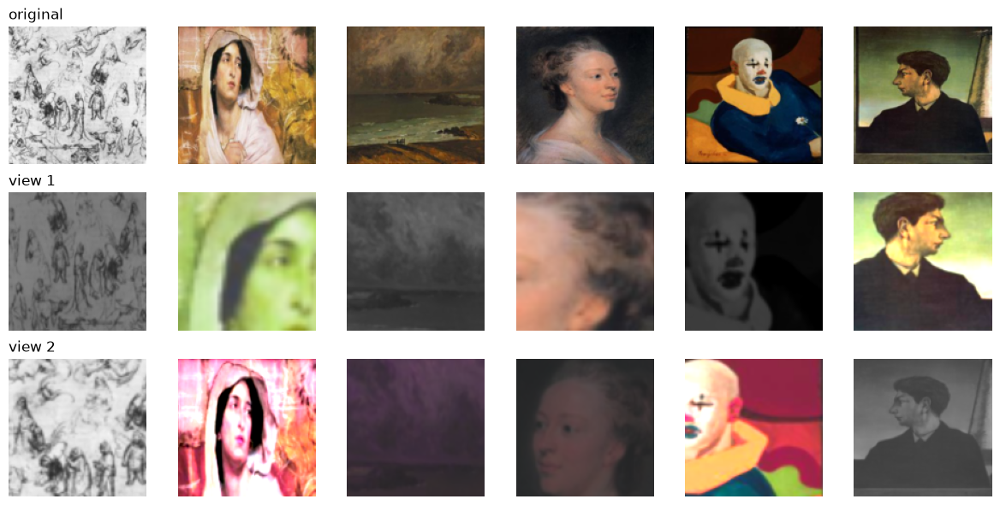

In [4]:
LUMA = torch.tensor([0.299, 0.587, 0.114], device=device).view(1, 3, 1, 1)
RGB_TO_YIQ = torch.tensor([[0.299, 0.587, 0.114],
                           [0.596, -0.274, -0.322],
                           [0.211, -0.523, 0.312]], device=device)
YIQ_TO_RGB = torch.linalg.inv(RGB_TO_YIQ)


def uniform(n: int, low: float, high: float) -> torch.Tensor:
    return torch.empty(n, device=device).uniform_(low, high)


def random_resized_crop(x: torch.Tensor, scale: tuple, ratio: tuple = (3 / 4, 4 / 3)) -> torch.Tensor:
    b, _, h, w = x.shape
    area = uniform(b, *scale) * h * w
    aspect = torch.exp(uniform(b, math.log(ratio[0]), math.log(ratio[1])))
    crop_w = torch.sqrt(area * aspect).clamp(max=w)
    crop_h = torch.sqrt(area / aspect).clamp(max=h)
    x0 = torch.rand(b, device=device) * (w - crop_w)
    y0 = torch.rand(b, device=device) * (h - crop_h)
    boxes = torch.stack([torch.arange(b, device=device, dtype=x.dtype), x0, y0, x0 + crop_w, y0 + crop_h], dim=1)
    return roi_align(x, boxes, output_size=(h, w), spatial_scale=1.0, sampling_ratio=1, aligned=True)   # 1 bilinear sample per output pixel


def gray(x: torch.Tensor) -> torch.Tensor:
    return (x * LUMA).sum(dim=1, keepdim=True)


def color_jitter(x: torch.Tensor, s: float) -> torch.Tensor:
    b = len(x)
    view = lambda t: t.view(b, 1, 1, 1)
    y = x * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s))                                  # brightness
    mean = gray(y).mean(dim=(2, 3), keepdim=True)
    y = (y - mean) * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s)) + mean                    # contrast
    g = gray(y)
    y = (y - g) * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s)) + g                          # saturation
    theta = uniform(b, -0.2 * s, 0.2 * s) * 2 * math.pi                                   # hue: rotate the I/Q chroma plane
    cos, sin = torch.cos(theta), torch.sin(theta)
    rot = torch.zeros(b, 3, 3, device=device)
    rot[:, 0, 0] = 1
    rot[:, 1, 1], rot[:, 1, 2], rot[:, 2, 1], rot[:, 2, 2] = cos, -sin, sin, cos
    m = YIQ_TO_RGB @ rot @ RGB_TO_YIQ                                                      # (b, 3, 3)
    y = torch.einsum("bij,bjhw->bihw", m, y)
    return y.clamp(0, 1)


def augment(x: torch.Tensor) -> torch.Tensor:
    """One random view of every image in the batch (float32, [0, 1], on the GPU)."""
    b = len(x)
    pick = lambda p: (torch.rand(b, device=device) < p).view(b, 1, 1, 1)
    x = random_resized_crop(x, CROP_SCALE)
    x = torch.where(pick(0.5), x.flip(dims=[3]), x)
    x = torch.where(pick(P_COLOR), color_jitter(x, COLOR_STRENGTH), x)
    x = torch.where(pick(P_GRAY), gray(x).expand(-1, 3, -1, -1), x)
    return x


# Example: 6 paintings, each with two random views
torch.manual_seed(SEED)
example = next(iter(eval_loader))["image"][:6].to(device)
rows = [example, augment(example), augment(example)]
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for r, (images, name) in enumerate(zip(rows, ["original", "view 1", "view 2"])):
    for c in range(6):
        axes[r, c].imshow(images[c].permute(1, 2, 0).cpu().numpy())
        axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left")
plt.tight_layout()
plt.show()

# Model

Encoder (no classification layer) -> `h`; projection head `Linear -> BN -> ReLU -> Linear` -> `z`.
`small_cnn` is the exact backbone of `deepcluster_clustering.ipynb` (without its MLP), so the two methods can be compared on the same architecture.

In [5]:
def conv_bn_relu(c_in: int, c_out: int) -> list[nn.Module]:
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]


def make_encoder(name: str) -> tuple[nn.Module, int]:
    if name == "resnet18":
        net = torchvision.models.resnet18(weights=None)
        net.fc = nn.Identity()
        return net, 512
    if name == "small_cnn":
        return nn.Sequential(
            *conv_bn_relu(3, 64), nn.MaxPool2d(2),
            *conv_bn_relu(64, 128), nn.MaxPool2d(2),
            *conv_bn_relu(128, 256), *conv_bn_relu(256, 256), nn.MaxPool2d(2),
            *conv_bn_relu(256, 512), *conv_bn_relu(512, 512), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        ), 512
    raise ValueError(f"unknown BACKBONE: {name}")


class SimCLR(nn.Module):
    def __init__(self, backbone: str, proj_dim: int):
        super().__init__()
        self.encoder, feat_dim = make_encoder(backbone)
        self.projector = nn.Sequential(
            nn.Linear(feat_dim, feat_dim, bias=False), nn.BatchNorm1d(feat_dim), nn.ReLU(inplace=True),
            nn.Linear(feat_dim, proj_dim),
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = self.encoder(x)
        return h, self.projector(h)


def nt_xent(z: torch.Tensor, temperature: float) -> tuple[torch.Tensor, torch.Tensor]:
    """
    z: (2B, d), rows i and i + B are the two views of painting i.
    Returns the loss and the share of views whose most similar other view is their partner.
    """
    z = F.normalize(z.float(), dim=1)
    sim = z @ z.T / temperature
    sim = sim.masked_fill(torch.eye(len(z), dtype=torch.bool, device=z.device), float("-inf"))   # not itself
    b = len(z) // 2
    partner = torch.cat([torch.arange(b, 2 * b), torch.arange(b)]).to(z.device)
    return F.cross_entropy(sim, partner), (sim.argmax(dim=1) == partner).float().mean()


torch.manual_seed(SEED)
model = SimCLR(BACKBONE, PROJ_DIM).to(device).to(memory_format=torch.channels_last)
n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"encoder {n_params(model.encoder):.2f}M | projector {n_params(model.projector):.2f}M parameters")

encoder 11.18M | projector 0.33M parameters


# Monitoring and evaluation helpers

* `embed_all`: encoder output `h` for every painting (no augmentation), in the fixed order of `eval_loader`.
* `quick_eval`: K-means with `K` clusters -> AMI vs style + silhouette. Cheap enough to run every few epochs; never used for training decisions.
* **Contrastive accuracy** (logged every epoch): how often a view's nearest neighbour in the batch is its partner. Close to 1 very early usually means the task is too easy (augmentations too weak, e.g. matching by colour histogram).

In [6]:
@torch.inference_mode()
def embed_all(net: SimCLR, loader: DataLoader) -> np.ndarray:
    net.eval()
    out = []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=AMP):
            out.append(net.encoder(x).float().cpu())
    return torch.cat(out).numpy()


known_style = meta["style"].notna().to_numpy()


def quick_eval(net: SimCLR) -> dict:
    features = make_preprocess().fit_transform(embed_all(net, eval_loader))
    labels = KMeans(n_clusters=K, n_init=3, random_state=SEED).fit_predict(features)
    return {
        "ami_style": adjusted_mutual_info_score(meta["style"][known_style], labels[known_style]),
        "ami_genre": adjusted_mutual_info_score(meta["genre"][known_style], labels[known_style]),
        "ami_artist": adjusted_mutual_info_score(meta["artist"][known_style], labels[known_style]),
        "silhouette": silhouette_score(features, labels, sample_size=min(5_000, len(labels)), random_state=SEED),
    }

# Training

In [7]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

total_steps = EPOCHS * len(train_loader)
warmup_steps = WARMUP_EPOCHS * len(train_loader)

def lr_factor(step: int) -> float:
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
torch.manual_seed(SEED)
log = []
start_epoch = 0


def snapshot_path(epoch: int) -> Path:
    return SNAPSHOT_DIR / f"epoch_{epoch:03d}.pt"


def save_snapshot(epoch: int) -> None:
    """Everything needed to evaluate or continue training from this epoch. Written to a temp file first, so a crash mid-save leaves no broken file."""
    SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)
    tmp = snapshot_path(epoch).with_suffix(".tmp")
    torch.save({
        "epoch": epoch,
        "config": {"backbone": BACKBONE, "proj_dim": PROJ_DIM, "temperature": TEMPERATURE, "crop_scale": CROP_SCALE,
                   "color_strength": COLOR_STRENGTH, "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE,
                   "split": SPLIT, "n_paintings": N_PAINTINGS, "seed": SEED},
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "log": log,
        "rng": {"torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None},
    }, tmp)
    tmp.replace(snapshot_path(epoch))


snapshots = sorted(SNAPSHOT_DIR.glob("epoch_*.pt")) if SNAPSHOT_DIR.exists() else []
if RESUME and snapshots:
    resume_from = snapshots[-1]                                  # newest (zero-padded names sort by epoch)
    ckpt = torch.load(resume_from, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    log = ckpt["log"]
    start_epoch = ckpt["epoch"]
    torch.set_rng_state(ckpt["rng"]["torch"].cpu())
    if ckpt["rng"]["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in ckpt["rng"]["cuda"]])
    print(f"resumed from {resume_from} at epoch {start_epoch} / {EPOCHS}")
else:
    row = {"epoch": 0, "loss": np.nan, "contrastive_acc": np.nan, **quick_eval(model)}
    log.append(row)
    print(f"epoch 0 (random init): AMI style {row['ami_style']:.3f} | silhouette {row['silhouette']:.3f}")

for epoch in tqdm(range(start_epoch + 1, EPOCHS + 1), desc="epochs", initial=start_epoch, total=EPOCHS):
    model.train()
    loss_sum, acc_sum = 0.0, 0.0
    for batch in tqdm(train_loader, desc=f"epoch {epoch}", leave=False):
        x = batch["image"].to(device, non_blocking=True)
        views = torch.cat([augment(x), augment(x)]).contiguous(memory_format=torch.channels_last)

        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=AMP):
            _, z = model(views)
        loss, acc = nt_xent(z, TEMPERATURE)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        loss_sum += loss.item()
        acc_sum += acc.item()

    row = {"epoch": epoch, "loss": loss_sum / len(train_loader), "contrastive_acc": acc_sum / len(train_loader)}
    if EVAL_EVERY and (epoch % EVAL_EVERY == 0 or epoch == EPOCHS):
        row |= quick_eval(model)
    log.append(row)
    extra = f" | AMI style {row['ami_style']:.3f} | silhouette {row['silhouette']:.3f}" if "ami_style" in row else ""
    print(f"epoch {epoch}: NT-Xent {row['loss']:.3f} | contrastive acc {row['contrastive_acc']:.1%}{extra}")
    if SNAPSHOT_EVERY and (epoch % SNAPSHOT_EVERY == 0 or epoch == EPOCHS):
        save_snapshot(epoch)

log = pd.DataFrame(log)

resumed from checkpoints_simclr_resnet_full_hard\simclr_resnet_full_hard_snapshots\epoch_100.pt at epoch 100 / 200


epochs:  50%|#####     | 100/200 [00:00<?, ?it/s]

epoch 101:   0%|          | 0/321 [00:25<?, ?it/s]

epoch 101: NT-Xent 4.214 | contrastive acc 81.1%


epoch 102:   0%|          | 0/321 [00:00<?, ?it/s]

epoch 102: NT-Xent 4.213 | contrastive acc 81.0%


... (192 outputs left out)

epoch 199:   0%|          | 0/321 [00:00<?, ?it/s]

epoch 199: NT-Xent 4.152 | contrastive acc 85.6%


epoch 200:   0%|          | 0/321 [00:00<?, ?it/s]

epoch 200: NT-Xent 4.149 | contrastive acc 85.6% | AMI style 0.152 | silhouette 0.091


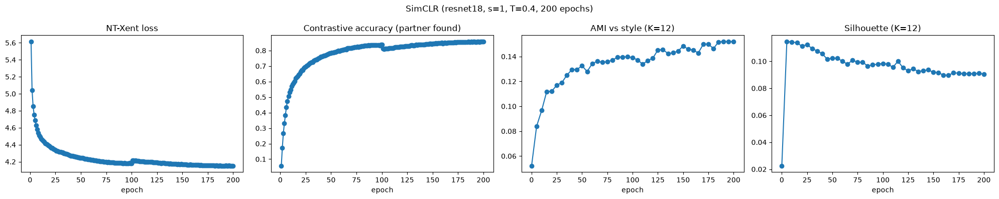

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
evals = log.dropna(subset=["ami_style"])
axes[0].plot(log["epoch"], log["loss"], marker="o");               axes[0].set(title="NT-Xent loss", xlabel="epoch")
axes[1].plot(log["epoch"], log["contrastive_acc"], marker="o");    axes[1].set(title="Contrastive accuracy (partner found)", xlabel="epoch")
axes[2].plot(evals["epoch"], evals["ami_style"], marker="o");      axes[2].set(title=f"AMI vs style (K={K})", xlabel="epoch")
axes[3].plot(evals["epoch"], evals["silhouette"], marker="o");     axes[3].set(title=f"Silhouette (K={K})", xlabel="epoch")
fig.suptitle(RUN_NAME)
plt.tight_layout()
plt.show()

# Evaluation

Same as in the other notebooks: embed, preprocess, K-means sweep, final K, metrics against the metadata.

embedding 512 -> features 512


K-means sweep:   0%|          | 0/10 [00:00<?, ?it/s]

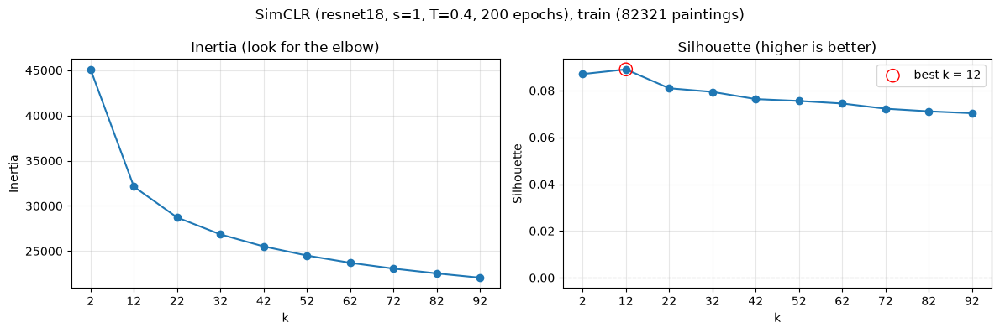

In [9]:
embed = embed_all(model, eval_loader)
preprocess = make_preprocess()
features = preprocess.fit_transform(embed)
print(f"embedding {embed.shape[1]} -> features {features.shape[1]}")

sweep = kmeans_sweep(features, K_SWEEP, seed=SEED)
plot_kmeans_sweep(sweep, title=f"{RUN_NAME}, {SPLIT} ({len(features)} paintings)")
plt.show()

In [10]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(features)
labels = kmeans.labels_

silhouette = silhouette_score(features, labels, sample_size=min(10_000, len(labels)), random_state=SEED)
print(f"Silhouette (k={K}) = {silhouette:.3f} on {len(labels)} paintings")
print("cluster sizes:", np.bincount(labels, minlength=K))

rows = []
for column in LABEL_COLUMNS:
    known = meta[column].notna().to_numpy()          # preprocessing set some labels to None
    y_true, y_pred = meta[column][known].to_numpy(), labels[known]
    rows.append({
        "labels": column,
        "classes": len(np.unique(y_true)),
        "paintings": int(known.sum()),
        "NMI": normalized_mutual_info_score(y_true, y_pred),
        "AMI": adjusted_mutual_info_score(y_true, y_pred),
        "ARI": adjusted_rand_score(y_true, y_pred),
    })
display(pd.DataFrame(rows).round(3))

Silhouette (k=12) = 0.089 on 82321 paintings
cluster sizes: [7288 8004 6276 5496 6709 5237 6358 7160 9316 8100 7857 4520]


,labels,classes,paintings,NMI,AMI,ARI
0,style,136,82301,0.155,0.152,0.052
1,genre,42,82301,0.201,0.200,0.129
2,artist,2200,82301,0.199,0.174,0.008


c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


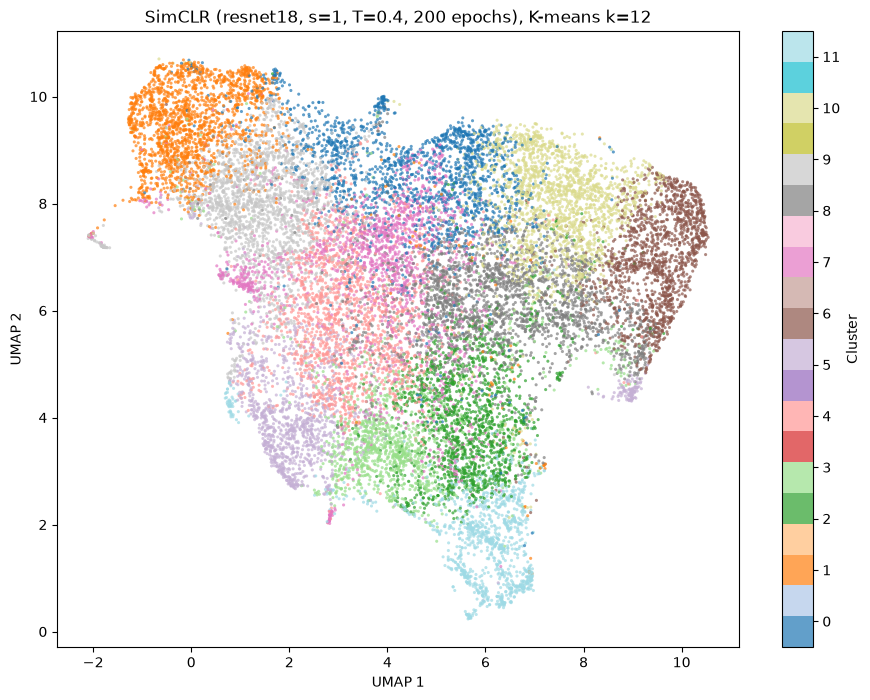

In [11]:
embedding_2d, idx_2d = umap_project(features, seed=SEED)
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"{RUN_NAME}, K-means k={K}")
plt.show()

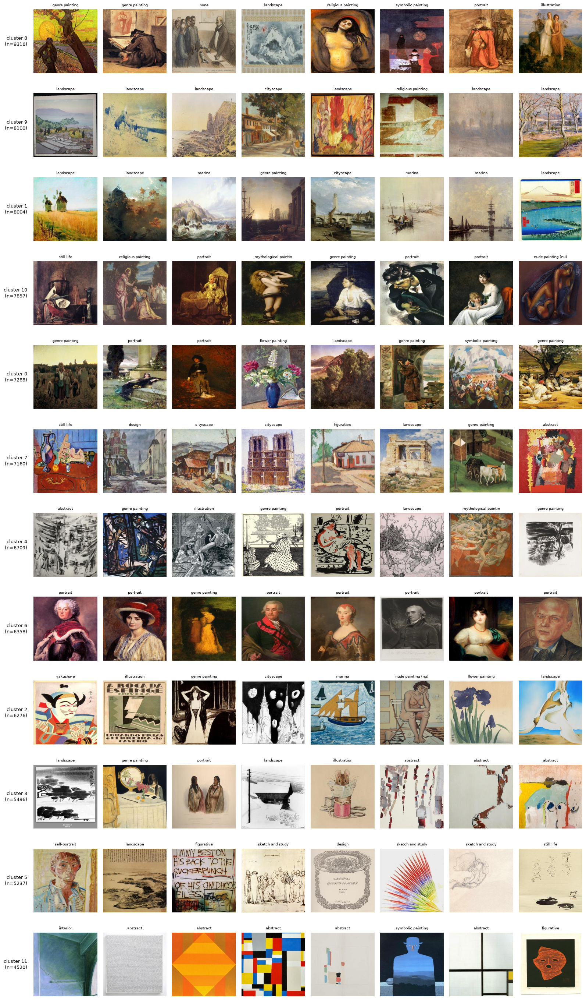

In [12]:
plot_cluster_samples(ds_cluster, labels, n_per_cluster=8, captions=meta["genre"], seed=SEED)

# UMAP + HDBSCAN

The SimCLR embedding is a continuous cloud, so K-means has to cut it at arbitrary places. HDBSCAN instead looks for **dense regions** and leaves paintings between them unassigned (**noise**, label `-1`).

1. UMAP (`min_dist=0`) to `UMAP_DIM` dimensions: it keeps the neighbourhood structure and packs neighbours tightly, which makes dense regions easier to find;
2. HDBSCAN finds the number of clusters itself.

Reading the results:
* metrics are computed on the clustered paintings only, so always read them together with the **noise share**;
* the K-means row is computed on the **same** clustered paintings, so the two methods are compared on equal ground;
* the silhouette in UMAP space is inflated by UMAP itself; both methods are scored in that space, so they are comparable with each other, but not with the silhouettes above.

In [13]:
umap_space = umap.UMAP(n_components=UMAP_DIM, n_neighbors=UMAP_NEIGHBORS, min_dist=0.0,
                       random_state=SEED).fit_transform(features)

hdbscan = HDBSCAN(min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE, min_samples=HDBSCAN_MIN_SAMPLES,
                  cluster_selection_method=HDBSCAN_SELECTION)
# hdbscan = DBSCAN(min_samples=HDBSCAN_MIN_SAMPLES)

hdb_labels = hdbscan.fit_predict(umap_space)
noise = hdb_labels == -1
n_hdb = len(np.unique(hdb_labels[~noise]))

print(f"HDBSCAN: {n_hdb} clusters | noise {noise.sum()} paintings ({noise.mean():.1%})")
print("cluster sizes (largest first):", np.sort(np.bincount(hdb_labels[~noise]))[::-1])

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN: 3 clusters | noise 497 paintings (0.6%)
cluster sizes (largest first): [81511   230    83]


In [14]:
kept = ~noise
rows = []
for name, pred in [(f"HDBSCAN ({n_hdb} clusters)", hdb_labels), (f"K-means (k={K})", labels)]:
    row = {"method": name, "clustered": int(kept.sum()), "noise": f"{noise.mean():.1%}"}
    if len(np.unique(pred[kept])) >= 2:
        row["silhouette (UMAP space)"] = silhouette_score(umap_space[kept], pred[kept],
                                                          sample_size=min(10_000, int(kept.sum())), random_state=SEED)
    for column in LABEL_COLUMNS:
        known = meta[column].notna().to_numpy() & kept
        row[f"AMI {column}"] = adjusted_mutual_info_score(meta[column][known], pred[known])
    for column in LABEL_COLUMNS:
        known = meta[column].notna().to_numpy() & kept
        row[f"ARI {column}"] = adjusted_rand_score(meta[column][known], pred[known])
    rows.append(row)
display(pd.DataFrame(rows).set_index("method").round(3))

,clustered,noise,silhouette (UMAP space),AMI style,AMI genre,AMI artist,ARI style,ARI genre,ARI artist
method,,,,,,,,,
HDBSCAN (3 clusters),81824,0.6%,0.246,0.004,0.007,0.005,-0.000,0.001,0.000
K-means (k=12),81824,0.6%,0.177,0.153,0.201,0.175,0.053,0.130,0.008


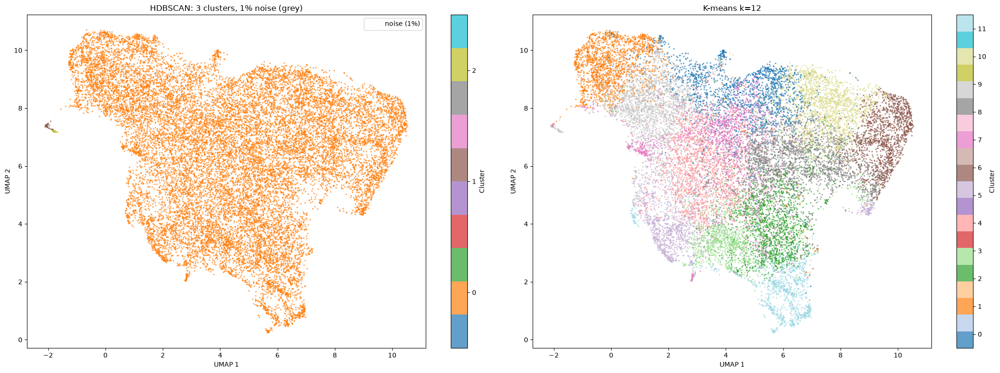

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
plot_clusters_2d(embedding_2d, hdb_labels[idx_2d], title=f"HDBSCAN: {n_hdb} clusters, {noise.mean():.0%} noise (grey)", ax=axes[0])
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"K-means k={K}", ax=axes[1])
plt.tight_layout()
plt.show()

In [16]:
# What each HDBSCAN cluster is "about": most common genre / style and their shares
def top(s: pd.Series):
    return s.value_counts().index[0] if s.notna().any() else None

def top_share(s: pd.Series):
    return s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan

summary = (
    pd.DataFrame({"cluster": hdb_labels, "genre": meta["genre"], "style": meta["style"]})
    .groupby("cluster")
    .agg(size=("genre", "size"),
         top_genre=("genre", top), top_genre_share=("genre", top_share),
         top_style=("style", top), top_style_share=("style", top_share))
    .sort_values("size", ascending=False)
)
display(summary.round(2))

,size,top_genre,top_genre_share,top_style,top_style_share
cluster,,,,,
0,81511,portrait,0.16,realism,0.10
-1,497,genre painting,0.15,impressionism,0.11
1,230,cityscape,0.96,post-impressionism,0.67
2,83,cityscape,1.00,impressionism,0.98


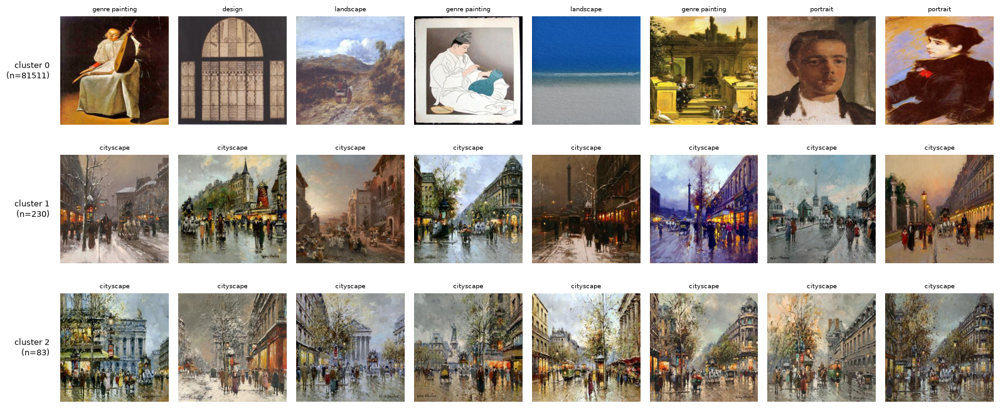

In [17]:
# Sample grid of the SHOW_CLUSTERS largest clusters (noise left out)
largest = summary.drop(index=-1, errors="ignore").index[:SHOW_CLUSTERS]
rows_shown = np.flatnonzero(np.isin(hdb_labels, largest))
plot_cluster_samples(ds_cluster.select(rows_shown), hdb_labels[rows_shown], n_per_cluster=8,
                     captions=meta["genre"].iloc[rows_shown].reset_index(drop=True), seed=SEED)

# Saving

In [18]:
# Reload: model = SimCLR(BACKBONE, PROJ_DIM); model.load_state_dict(torch.load(path)["state_dict"])
if SAVE_TO is not None:
    Path(SAVE_TO).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "config": {
            "backbone": BACKBONE, "proj_dim": PROJ_DIM, "temperature": TEMPERATURE,
            "crop_scale": CROP_SCALE, "color_strength": COLOR_STRENGTH, "p_color": P_COLOR, "p_gray": P_GRAY,
            "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE,
            "split": SPLIT, "n_paintings": N_PAINTINGS, "seed": SEED,
        },
        "state_dict": model.state_dict(),
        "log": log.to_dict(orient="list"),
    }, SAVE_TO)
    print(f"saved {SAVE_TO}")

saved checkpoints_simclr_resnet_full_hard\simclr_resnet_full_hard.pt


# Saving the clustering

Everything `cluster_quality.ipynb` needs, in one file: the cluster labels, which dataset rows they belong to (`cluster_idx`), the space K-means ran in (`features`, after preprocessing), the fitted preprocessing + K-means (embedding -> label), and where the encoder came from.

In [ ]:
# Input of cluster_quality.ipynb. Reload: c = joblib.load(path); c["labels"][i] is the cluster of dataset row c["cluster_idx"][i]
if SAVE_CLUSTERING is not None:
    Path(SAVE_CLUSTERING).parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({
        "name": RUN_NAME,
        "representation": "simclr",
        "method": "kmeans",
        "k": K,
        "labels": np.asarray(labels, dtype=np.int32),
        "split": SPLIT,
        "n_paintings": N_PAINTINGS,
        "seed": SEED,
        "cluster_idx": np.asarray(cluster_idx, dtype=np.int64),   # row i of labels / features = dataset row cluster_idx[i]
        "features": np.asarray(features, dtype=np.float16),       # the space K-means ran in (after preprocessing)
        "clusterer": make_pipeline(*[step for _, step in preprocess.steps], kmeans),   # embedding -> label
        "encoder": {"type": "simclr", "checkpoint": str(SAVE_TO) if SAVE_TO else None, "backbone": BACKBONE, "proj_dim": PROJ_DIM,
                    "epochs": EPOCHS, "img_size": IMG_SIZE, "transform": "RESIZE_128"},
    }, SAVE_CLUSTERING)
    print(f"saved {SAVE_CLUSTERING}: {len(labels)} paintings, {K} clusters, features {features.shape[1]}-d")